# Q3-Q4(a): data preparation and verification
Run the downloader first. All 716 District-11 sensors are retained in metadata order. Each complete group of three five-minute vehicle counts is summed. Partial bins remain masked targets; inputs use split-local forward fill and a training-only median fallback.

In [1]:
from pathlib import Path
import sys, subprocess, json
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').is_dir()
def run(script,*args):
    command=[sys.executable,str(ROOT/'src'/script),*args]
    log=ROOT/'results'/(script.replace('.py','')+('_'+args[-1] if args else '')+'.log')
    with log.open('w',encoding='utf-8') as f:
        result=subprocess.run(command,cwd=ROOT,stdout=f,stderr=subprocess.STDOUT)
    print(log.read_text(encoding='utf-8')[-16000:])
    result.check_returncode()
def show(name):
    display(Image(filename=str(ROOT/'figures'/name)))

In [2]:
run('prepare.py')

{
  "nodes": 716,
  "raw": {
    "2020": {
      "rows": 105408,
      "missing_or_negative": 3095400,
      "zero_readings": 213158,
      "total": 75472128
    },
    "2021": {
      "rows": 105120,
      "missing_or_negative": 4541266,
      "zero_readings": 188860,
      "total": 75265920
    }
  },
  "splits": {
    "train": {
      "timestamps": 35136,
      "windows": 35125,
      "start": "2020-01-01 00:00:00",
      "end": "2020-12-31 23:45:00",
      "missing_bins": 1034655,
      "valid_target_fraction": 0.9588726980111121
    },
    "val": {
      "timestamps": 8640,
      "windows": 8629,
      "start": "2021-01-01 00:00:00",
      "end": "2021-03-31 23:45:00",
      "missing_bins": 376574,
      "valid_target_fraction": 0.9391271596316987
    },
    "test": {
      "timestamps": 26400,
      "windows": 26389,
      "start": "2021-04-01 00:00:00",
      "end": "2021-12-31 23:45:00",
      "missing_bins": 1139060,
      "valid_target_fraction": 0.939739927205011
    }
  },


## Leakage and implementation checks
Chronological boundaries are applied before filling. Windows contain eight inputs followed by four targets and cannot cross those boundaries. The checks also verify graph gradients and identical shared initialization.

In [3]:
run('checks.py')

PASS: ordering, exact dates, split-local windows, target masks, training statistics, normalized graphs, gradients, shared initialization.



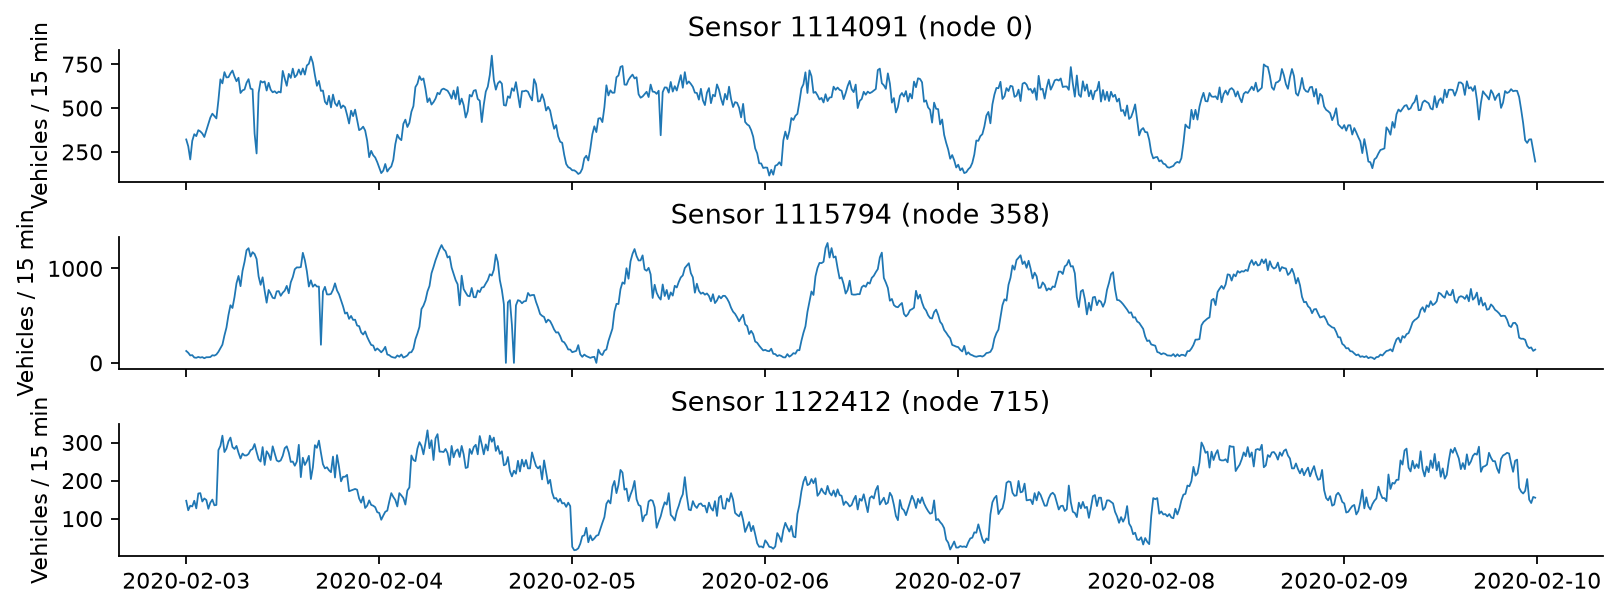

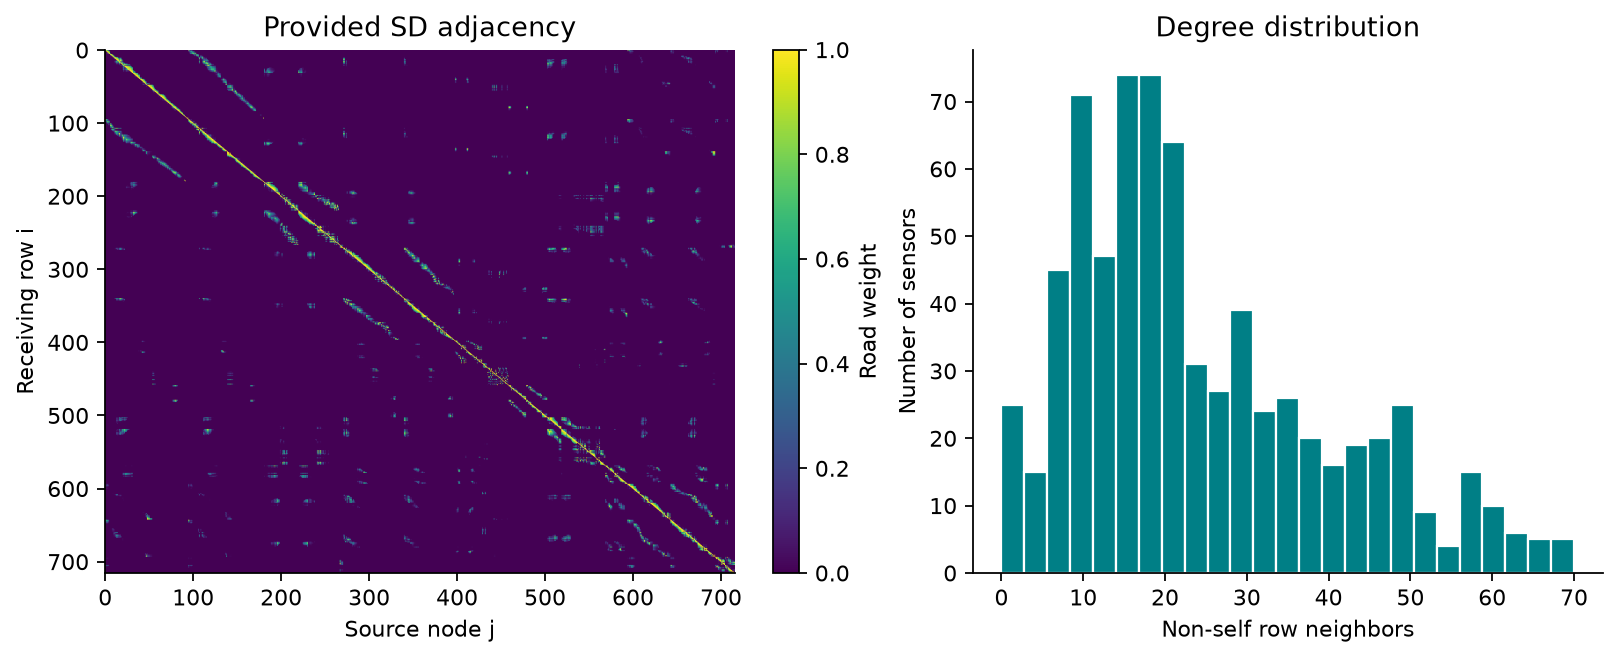

In [4]:
show('q3_week.png')
show('q3_graph.png')